--- Logistic Regression Performance ---
ROC-AUC Score: 0.6119 (Baseline = 0.5000)
Precision:     0.6138
Recall:        0.8507

--- Confusion Matrix ---
[[ 2666  9642]
 [ 2690 15327]]


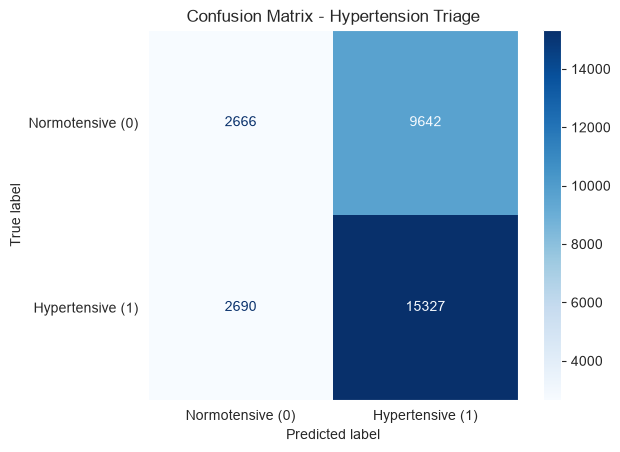


--- Top 5 Highest Risk Individuals (Ngozi's Triage Priority) ---
       Actual_High_BP  Predicted_Risk_Score  Predicted_Class
113                 1                0.8603                1
20580               1                0.8512                1
16951               1                0.8509                1
14179               1                0.8438                1
21401               1                0.8388                1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Load data
try:
    df = pd.read_parquet("data/analysis_sample.parquet")
except Exception:
    df = pd.read_csv(r"C:\Users\ugochukwu.emenike\PycharmProjects\PythonProject\powerbi\analysis_sample.csv")

# 2. Drop rows missing BP values before defining binary target
df = df.dropna(subset=['SYSTOLIC_BP', 'DIASTOLIC_BP']).copy()

# 3. Define binary classification target: 1 if Systolic >= 140 or Diastolic >= 90, else 0
df['HIGH_BP_FLAG'] = np.where(
    (df['SYSTOLIC_BP'] >= 140) | (df['DIASTOLIC_BP'] >= 90), 1, 0
)

# 4. Strict leakage exclusion
leakage_cols = [
    'SYSTOLIC_BP', 'DIASTOLIC_BP', 'DIAGNOSED_HYPERTENSION',
    'BP_CATEGORY', 'SAMPLE_ID', 'HIGH_BP_FLAG'
]
X = df.drop(columns=[col for col in leakage_cols if col in df.columns])
y = df['HIGH_BP_FLAG']

# 5. Stratified train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 6. Pipeline: Scale numeric inputs, one-hot encode categories
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numeric_features),
        ('cat', cat_pipeline, categorical_features)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 7. Fit Logistic Regression
model.fit(X_train, y_train)

# 8. Generate continuous risk scores (probabilities) and binary predictions
# predict_proba returns [prob_class_0, prob_class_1]; we take column 1 for positive risk
risk_scores = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

# 9. Compute evaluation metrics
roc_auc = roc_auc_score(y_test, risk_scores)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("--- Logistic Regression Performance ---")
print(f"ROC-AUC Score: {roc_auc:.4f} (Baseline = 0.5000)")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}\n")

# 10. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("--- Confusion Matrix ---")
print(cm)

# Display matrix visualization
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normotensive (0)', 'Hypertensive (1)'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Hypertension Triage")
plt.grid(False)
plt.show()

# Sample of Ngozi's requested risk table
risk_table = pd.DataFrame({
    'Actual_High_BP': y_test.values,
    'Predicted_Risk_Score': np.round(risk_scores, 4),
    'Predicted_Class': y_pred
}).sort_values(by='Predicted_Risk_Score', ascending=False)

print("\n--- Top 5 Highest Risk Individuals (Ngozi's Triage Priority) ---")
print(risk_table.head())